# BÀI TẬP LỚN MÔN ỨNG DỤNG AI
## Đề tài: Dự đoán nhân sự nghỉ việc (Employee Attrition Prediction)
### Phần IV: Cài đặt thử nghiệm và Kết quả nghiên cứu

**Pipeline:** tiền xử lý → EDA → huấn luyện 5 mô hình (4 ML + 1 Deep Learning) với Cross-Validation → metrics, ma trận nhầm lẫn, độ quan trọng đặc trưng.

**Mô hình:** Logistic Regression · Random Forest · SVM · XGBoost · MLP (Deep Learning)

**Lưu ý:** Lớp dương (positive = 1) là "Nghỉ việc" (`Attrition = Yes`). Mục tiêu là tối đa hóa **Recall** cho lớp nghỉ việc.

In [31]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, balanced_accuracy_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

%matplotlib inline
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"

CSV_PATH = "nhansunghiviec.csv"   # đặt cùng thư mục với notebook
OUT_DIR = "ket_qua"               # chỉ dùng để lưu các bảng .csv
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## BƯỚC 1: Nạp và kiểm tra dữ liệu

In [32]:
df = pd.read_csv(CSV_PATH)
print(f"Kích thước dữ liệu: {df.shape[0]} bản ghi, {df.shape[1]} cột")
print(f"Các cột: {list(df.columns)}")
print("\nSố giá trị thiếu (NaN) toàn bộ: " + str(int(df.isnull().sum().sum())))
print("\nThống kê mô tả các biến số:")
display(df[["Age", "MonthlyIncome", "YearsAtCompany", "JobSatisfaction"]].describe().round(2))

n_total = len(df)
n_leave = int((df["Attrition"] == "Yes").sum())
n_stay = int((df["Attrition"] == "No").sum())
rate = n_leave / n_total * 100
print("\nPhân phối nhãn Attrition:")
print(f"  - Nghỉ việc (Yes): {n_leave}  ({rate:.2f}%)")
print(f"  - Ở lại     (No) : {n_stay}  ({100-rate:.2f}%)")
print(f"  -> Dữ liệu MẤT CÂN BẰNG (~{rate:.0f}% lớp thiểu số)")
print(f"  - Số bản ghi trùng lặp: {int(df.duplicated().sum())}")

Kích thước dữ liệu: 1470 bản ghi, 6 cột
Các cột: ['Age', 'MonthlyIncome', 'OverTime', 'JobSatisfaction', 'YearsAtCompany', 'Attrition']

Số giá trị thiếu (NaN) toàn bộ: 0

Thống kê mô tả các biến số:


,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction
count,1470.00,1470.00,1470.00,1470.00
mean,36.92,6502.93,7.01,2.73
std,9.14,4707.96,6.13,1.10
min,18.00,1009.00,0.00,1.00
25%,30.00,2911.00,3.00,2.00
50%,36.00,4919.00,5.00,3.00
75%,43.00,8379.00,9.00,4.00
max,60.00,19999.00,40.00,4.00



Phân phối nhãn Attrition:
  - Nghỉ việc (Yes): 237  (16.12%)
  - Ở lại     (No) : 1233  (83.88%)
  -> Dữ liệu MẤT CÂN BẰNG (~16% lớp thiểu số)
  - Số bản ghi trùng lặp: 0


## BƯỚC 2: Trực quan hóa dữ liệu (EDA)

### 2.1 Phân bố tình trạng nghỉ việc

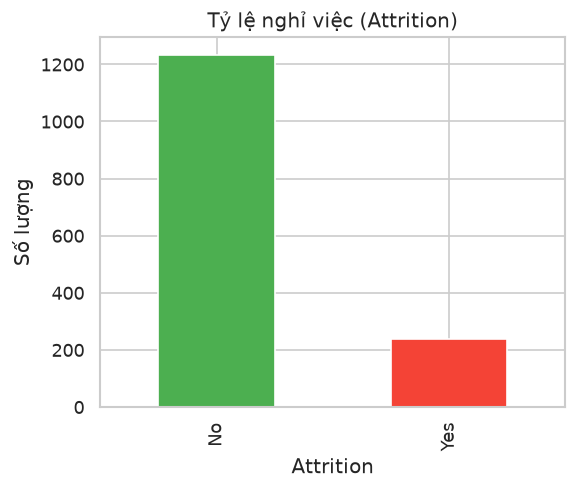

In [33]:
plt.figure(figsize=(5, 4))
df['Attrition'].value_counts().plot(kind='bar', color=['#4CAF50', '#F44336'])
plt.title('Tỷ lệ nghỉ việc (Attrition)')
plt.ylabel('Số lượng')
plt.show()

### 2.2 Phân bố các biến số (Tuổi, Thu nhập, Thâm niên)

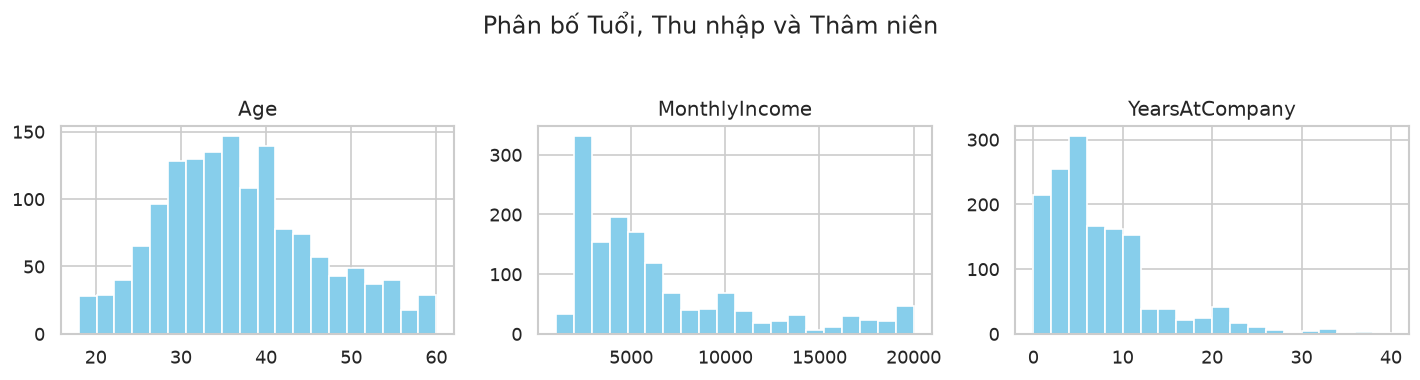

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
df[['Age', 'MonthlyIncome', 'YearsAtCompany']].hist(bins=20, ax=axes, color='skyblue')
plt.suptitle('Phân bố Tuổi, Thu nhập và Thâm niên', y=1.05)
fig.tight_layout()
plt.show()

### 2.3 Nghỉ việc theo mức độ hài lòng

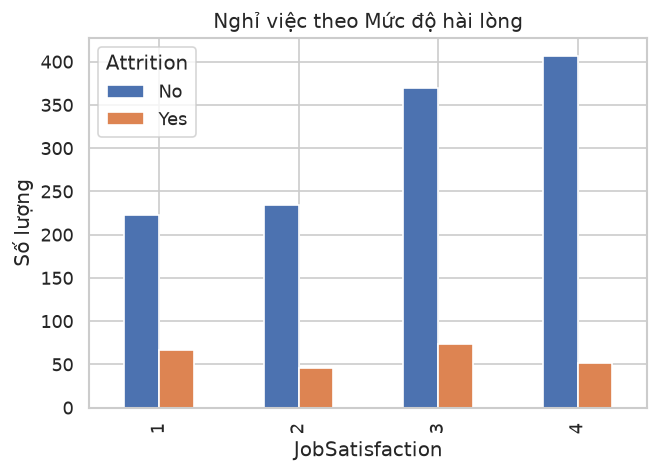

In [35]:
crosstab_satisfaction = pd.crosstab(df['JobSatisfaction'], df['Attrition'])
crosstab_satisfaction.plot(kind='bar', stacked=False, figsize=(6, 4))
plt.title('Nghỉ việc theo Mức độ hài lòng')
plt.ylabel('Số lượng')
plt.show()

### 2.4 Ma trận tương quan

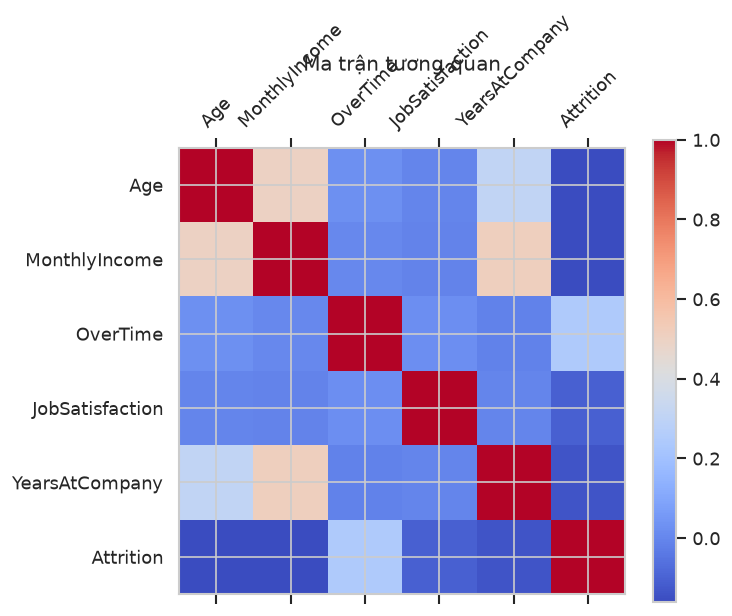

In [36]:
df_corr = df.copy()
df_corr['Attrition'] = df_corr['Attrition'].map({'Yes': 1, 'No': 0})
df_corr['OverTime'] = df_corr['OverTime'].map({'Yes': 1, 'No': 0})

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.matshow(df_corr.corr(), cmap='coolwarm')
plt.xticks(range(len(df_corr.columns)), df_corr.columns, rotation=45)
plt.yticks(range(len(df_corr.columns)), df_corr.columns)
plt.colorbar(im)
plt.title('Ma trận tương quan', y=1.15)
plt.show()

## BƯỚC 3: Tiền xử lý dữ liệu

### 3.1 Mã hóa nhãn và chia Train/Test (80/20, stratify)

In [37]:
df2 = df.copy()

# Mã hóa thủ công (không dùng LabelEncoder)
df2['Attrition'] = df2['Attrition'].map({'Yes': 1, 'No': 0})
df2['OverTime'] = df2['OverTime'].map({'Yes': 1, 'No': 0})

X = df2.drop('Attrition', axis=1)
y = df2['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

print(f"Kích thước tập Train ban đầu: X_train {X_train.shape}")
print(f"Tỷ lệ nhãn ban đầu:\n{y_train.value_counts()}")

Kích thước tập Train ban đầu: X_train (1176, 5)
Tỷ lệ nhãn ban đầu:
Attrition
0    986
1    190
Name: count, dtype: int64


### 3.2 Chuẩn hóa Z-score thủ công (mean/std lấy từ tập Train)

In [38]:
cols_to_scale = ['Age', 'MonthlyIncome', 'YearsAtCompany']
for col in cols_to_scale:
    mean_val = X_train[col].mean()
    std_val = X_train[col].std()
    X_train[col] = (X_train[col] - mean_val) / std_val
    X_test[col] = (X_test[col] - mean_val) / std_val

display(X_train[cols_to_scale].describe().round(3))

,Age,MonthlyIncome,YearsAtCompany
count,1176.000,1176.000,1176.000
mean,-0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.070,-1.189,-1.158
25%,-0.762,-0.773,-0.665
50%,-0.109,-0.331,-0.337
75%,0.654,0.403,0.485
max,2.506,2.886,4.921


### 3.3 Oversampling thủ công lớp thiểu số

Hàm `oversample` được tách riêng để dùng lại **bên trong từng fold** của Cross-Validation (Bước 5), tránh rò rỉ dữ liệu.

In [39]:
def oversample(X_tr, y_tr, seed=RANDOM_STATE):
    """Nhân bản ngẫu nhiên (có hoàn lại) lớp nghỉ việc cho bằng lớp ở lại."""
    data = pd.concat([X_tr, y_tr], axis=1)
    class_0 = data[data['Attrition'] == 0]
    class_1 = data[data['Attrition'] == 1]
    class_1_over = class_1.sample(len(class_0), replace=True, random_state=seed)
    balanced = pd.concat([class_0, class_1_over], axis=0)
    return balanced.drop('Attrition', axis=1), balanced['Attrition']

# Tập train đã cân bằng, dùng để huấn luyện mô hình cuối cùng (Bước 6)
X_train_resampled, y_train_resampled = oversample(X_train, y_train)

print("Sau khi cân bằng dữ liệu thủ công (Oversampling):")
print(f"Kích thước tập Train mới: {X_train_resampled.shape}")
print(f"Tỷ lệ nhãn sau cân bằng:\n{y_train_resampled.value_counts()}")

FEATURES = list(X.columns)
print(f"\nCác đặc trưng sử dụng: {FEATURES}")

Sau khi cân bằng dữ liệu thủ công (Oversampling):
Kích thước tập Train mới: (1972, 5)
Tỷ lệ nhãn sau cân bằng:
Attrition
0    986
1    986
Name: count, dtype: int64

Các đặc trưng sử dụng: ['Age', 'MonthlyIncome', 'OverTime', 'JobSatisfaction', 'YearsAtCompany']


## BƯỚC 4: Cấu hình các mô hình

In [40]:
def make_pipelines():
    return {
        "Logistic Regression": Pipeline([
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                       random_state=RANDOM_STATE)),
        ]),
        "Random Forest": Pipeline([
            ("clf", RandomForestClassifier(n_estimators=300, max_depth=None,
                                           class_weight="balanced",
                                           random_state=RANDOM_STATE, n_jobs=-1)),
        ]),
        "SVM": Pipeline([
            ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True,
                        class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        "XGBoost": Pipeline([
            ("clf", XGBClassifier(n_estimators=300, max_depth=4,
                                  learning_rate=0.1, subsample=0.9,
                                  colsample_bytree=0.9, reg_lambda=1.0,
                                  eval_metric="logloss",
                                  random_state=RANDOM_STATE, n_jobs=-1)),
        ]),
        "MLP (Deep Learning)": Pipeline([
            ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                                  solver="adam", alpha=1e-3, batch_size=32,
                                  learning_rate_init=1e-3, max_iter=500,
                                  early_stopping=True, n_iter_no_change=20,
                                  validation_fraction=0.15,
                                  random_state=RANDOM_STATE)),
        ]),
    }

MODELS = make_pipelines()

descriptions = {
    "Logistic Regression": "Hồi quy logistic (tuyến tính), class_weight='balanced'",
    "Random Forest": "300 cây quyết định, class_weight='balanced'",
    "SVM": "Kernel RBF, C=1.0, gamma='scale', probability=True",
    "XGBoost": "Gradient Boosting, 300 estimators, max_depth=4, lr=0.1",
    "MLP (Deep Learning)": "Mạng neural 2 lớp ẩn (64,32), ReLU, Adam, early_stopping",
}
print("Các mô hình được cấu hình:")
for name, desc in descriptions.items():
    print(f"  {name:22s}: {desc}")

Các mô hình được cấu hình:
  Logistic Regression   : Hồi quy logistic (tuyến tính), class_weight='balanced'
  Random Forest         : 300 cây quyết định, class_weight='balanced'
  SVM                   : Kernel RBF, C=1.0, gamma='scale', probability=True
  XGBoost               : Gradient Boosting, 300 estimators, max_depth=4, lr=0.1
  MLP (Deep Learning)   : Mạng neural 2 lớp ẩn (64,32), ReLU, Adam, early_stopping


## BƯỚC 5: Cross-Validation (5-fold) trên tập huấn luyện


In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "balanced_accuracy"]

def eval_fold(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

print("Tiến hành đánh giá chéo 5-fold (oversampling trong từng fold)...\n")
cv_results = {}
for name, pipe in MODELS.items():
    scores = {m: [] for m in metric_names}
    for tr_idx, va_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train.iloc[va_idx]

        X_tr_bal, y_tr_bal = oversample(X_tr, y_tr)   # chỉ cân bằng phần train của fold
        model = clone(pipe)
        model.fit(X_tr_bal, y_tr_bal)

        res = eval_fold(y_va, model.predict(X_va), model.predict_proba(X_va)[:, 1])
        for m in metric_names:
            scores[m].append(res[m])

    cv_results[name] = {m: np.array(v) for m, v in scores.items()}
    print(f"[{name}]")
    for m in metric_names:
        print(f"    {m:18s}: {np.mean(scores[m]):.4f}  (+/- {np.std(scores[m]):.4f})")
    print()

Tiến hành đánh giá chéo 5-fold (oversampling trong từng fold)...

[Logistic Regression]
    accuracy          : 0.6888  (+/- 0.0306)
    precision         : 0.2954  (+/- 0.0421)
    recall            : 0.6737  (+/- 0.1184)
    f1                : 0.4101  (+/- 0.0620)
    roc_auc           : 0.7429  (+/- 0.0499)
    balanced_accuracy : 0.6827  (+/- 0.0600)

[Random Forest]
    accuracy          : 0.8231  (+/- 0.0203)
    precision         : 0.4435  (+/- 0.0622)
    recall            : 0.3211  (+/- 0.0632)
    f1                : 0.3679  (+/- 0.0567)
    roc_auc           : 0.7219  (+/- 0.0283)
    balanced_accuracy : 0.6205  (+/- 0.0293)

[SVM]
    accuracy          : 0.7322  (+/- 0.0292)
    precision         : 0.3322  (+/- 0.0436)
    recall            : 0.6474  (+/- 0.0858)
    f1                : 0.4386  (+/- 0.0558)
    roc_auc           : 0.7533  (+/- 0.0488)
    balanced_accuracy : 0.6979  (+/- 0.0480)

[XGBoost]
    accuracy          : 0.7891  (+/- 0.0244)
    precision         

In [42]:
cv_table = pd.DataFrame({"Model": list(cv_results.keys())})
for m in metric_names:
    cv_table[m] = [cv_results[name][m].mean() for name in MODELS]

print("BẢNG TỔNG HỢP KẾT QUẢ CROSS-VALIDATION (trung bình 5-fold)")
display(cv_table.round(4))
cv_table.to_csv(os.path.join(OUT_DIR, "bang_cv.csv"), index=False)

BẢNG TỔNG HỢP KẾT QUẢ CROSS-VALIDATION (trung bình 5-fold)


,Model,accuracy,precision,recall,f1,roc_auc,balanced_accuracy
0,Logistic Regression,0.6888,0.2954,0.6737,0.4101,0.7429,0.6827
1,Random Forest,0.8231,0.4435,0.3211,0.3679,0.7219,0.6205
2,SVM,0.7322,0.3322,0.6474,0.4386,0.7533,0.6979
3,XGBoost,0.7891,0.3576,0.3737,0.3630,0.6955,0.6214
4,MLP (Deep Learning),0.7543,0.3576,0.6316,0.4554,0.7570,0.7048


## BƯỚC 6: Huấn luyện trên Train và đánh giá trên Test (holdout 20%)

In [43]:
fitted = {}
test_rows = []
y_pred_dict = {}
for name, pipe in MODELS.items():
    pipe.fit(X_train_resampled, y_train_resampled)
    fitted[name] = pipe
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred_dict[name] = y_pred

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
    })

test_table = pd.DataFrame(test_rows)
print("Bảng metrics trên tập Test (lớp dương = Nghỉ việc):")
display(test_table.round(4))
test_table.to_csv(os.path.join(OUT_DIR, "bang_test_metrics.csv"), index=False)

print("\nXếp hạng theo Recall (giảm dần) - ưu tiên phát hiện nhân viên nghỉ việc:")
ranked = test_table.sort_values(["Recall", "F1-score"], ascending=False)
display(ranked.round(4)[["Model", "Recall", "F1-score", "ROC-AUC", "Accuracy"]])

Bảng metrics trên tập Test (lớp dương = Nghỉ việc):


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Balanced Acc
0,Logistic Regression,0.7177,0.3364,0.7872,0.4713,0.7778,0.7458
1,Random Forest,0.7925,0.3056,0.2340,0.2651,0.7375,0.5664
2,SVM,0.7313,0.3333,0.6809,0.4476,0.7772,0.7109
3,XGBoost,0.7721,0.3077,0.3404,0.3232,0.7076,0.5973
4,MLP (Deep Learning),0.7143,0.3093,0.6383,0.4167,0.7231,0.6835



Xếp hạng theo Recall (giảm dần) - ưu tiên phát hiện nhân viên nghỉ việc:


,Model,Recall,F1-score,ROC-AUC,Accuracy
0,Logistic Regression,0.7872,0.4713,0.7778,0.7177
2,SVM,0.6809,0.4476,0.7772,0.7313
4,MLP (Deep Learning),0.6383,0.4167,0.7231,0.7143
3,XGBoost,0.3404,0.3232,0.7076,0.7721
1,Random Forest,0.2340,0.2651,0.7375,0.7925


## BƯỚC 7: Ma trận nhầm lẫn và Classification Report (tập Test)

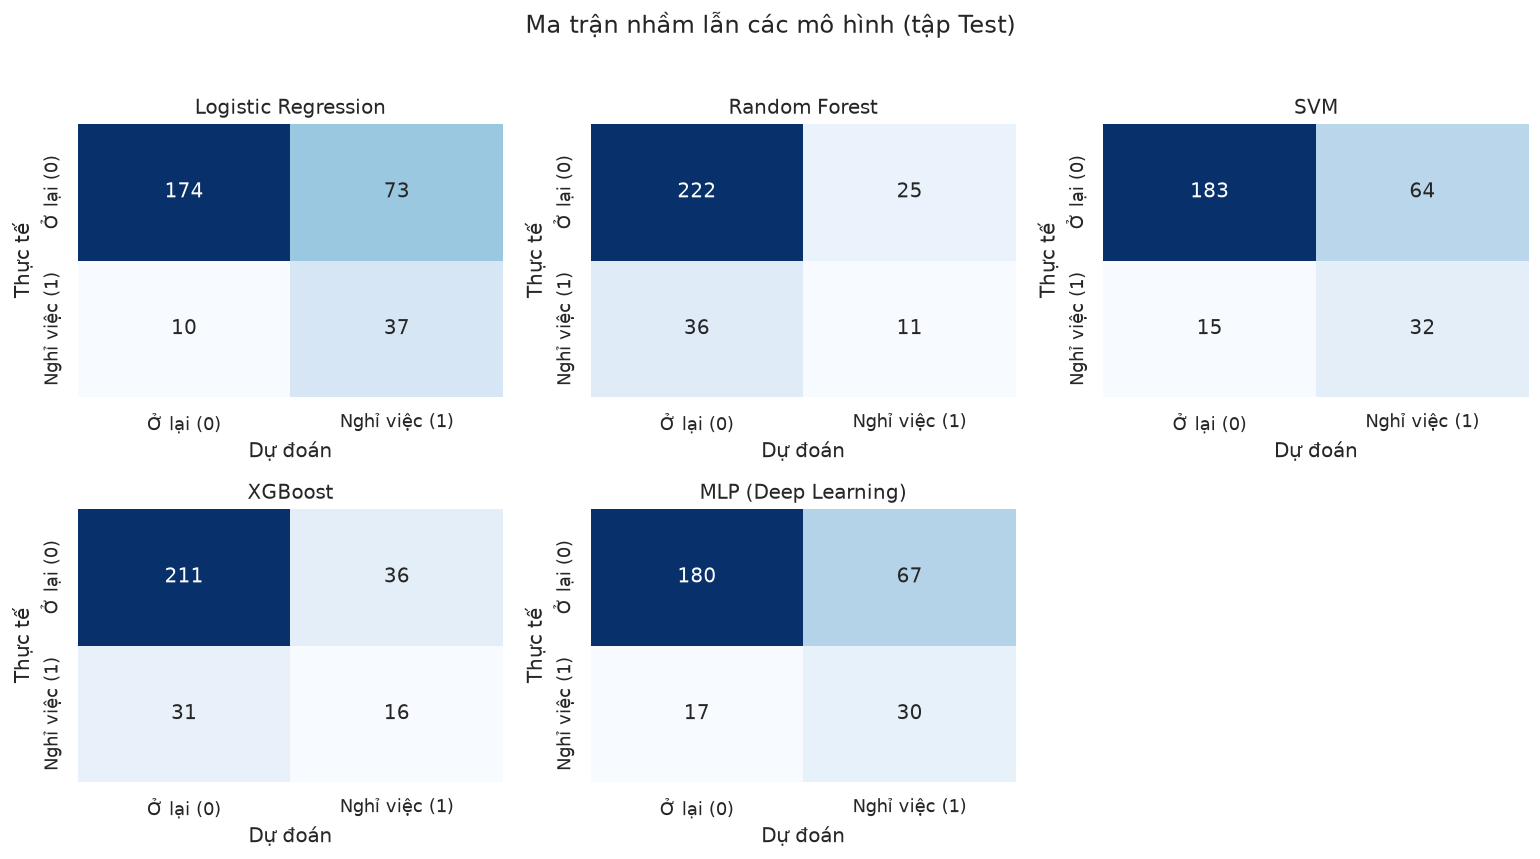

In [44]:
labels_name = ["Ở lại (0)", "Nghỉ việc (1)"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.ravel()
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, y_pred_dict[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels_name, yticklabels=labels_name, ax=ax)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.set_title(name)
for ax in axes[len(MODELS):]:
    ax.axis("off")
fig.suptitle("Ma trận nhầm lẫn các mô hình (tập Test)", y=1.02)
fig.tight_layout()
plt.show()

In [45]:
for name in MODELS:
    y_pred = y_pred_dict[name]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"\n--- {name} ---")
    print(f"  Ma trận nhầm lẫn:  TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(classification_report(y_test, y_pred, target_names=labels_name,
                                digits=4, zero_division=0))


--- Logistic Regression ---
  Ma trận nhầm lẫn:  TN=174, FP=73, FN=10, TP=37
               precision    recall  f1-score   support

    Ở lại (0)     0.9457    0.7045    0.8074       247
Nghỉ việc (1)     0.3364    0.7872    0.4713        47

     accuracy                         0.7177       294
    macro avg     0.6410    0.7458    0.6394       294
 weighted avg     0.8482    0.7177    0.7537       294


--- Random Forest ---
  Ma trận nhầm lẫn:  TN=222, FP=25, FN=36, TP=11
               precision    recall  f1-score   support

    Ở lại (0)     0.8605    0.8988    0.8792       247
Nghỉ việc (1)     0.3056    0.2340    0.2651        47

     accuracy                         0.7925       294
    macro avg     0.5830    0.5664    0.5721       294
 weighted avg     0.7718    0.7925    0.7810       294


--- SVM ---
  Ma trận nhầm lẫn:  TN=183, FP=64, FN=15, TP=32
               precision    recall  f1-score   support

    Ở lại (0)     0.9242    0.7409    0.8225       247
Nghỉ việc (

## BƯỚC 8: Độ quan trọng của đặc trưng

- Random Forest / XGBoost: `feature_importances_`
- Logistic Regression: |hệ số| (trên dữ liệu đã scale)
- SVM / MLP: Permutation Importance (mất điểm ROC-AUC)

In [46]:
fi_records = {}

# Random Forest & XGBoost
for name in ["Random Forest", "XGBoost"]:
    imp = fitted[name].named_steps["clf"].feature_importances_
    fi_records[name] = imp
    print(f"[{name}] feature_importances_:")
    for i in np.argsort(imp)[::-1]:
        print(f"    {FEATURES[i]:20s}: {imp[i]:.4f}")
    print()

# Logistic Regression
coef = np.abs(fitted["Logistic Regression"].named_steps["clf"].coef_[0])
fi_records["Logistic Regression"] = coef
print("[Logistic Regression] |hệ số| (trên dữ liệu chuẩn hóa):")
for i in np.argsort(coef)[::-1]:
    print(f"    {FEATURES[i]:20s}: {coef[i]:.4f}")
print()

# SVM & MLP: permutation importance trên tập test
for name in ["SVM", "MLP (Deep Learning)"]:
    r = permutation_importance(fitted[name], X_test, y_test, scoring="roc_auc",
                               n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    imp = r.importances_mean
    fi_records[name] = imp
    print(f"[{name}] Permutation Importance (giảm ROC-AUC):")
    for i in np.argsort(imp)[::-1]:
        print(f"    {FEATURES[i]:20s}: {imp[i]:.4f}")
    print()

[Random Forest] feature_importances_:
    MonthlyIncome       : 0.3486
    Age                 : 0.2742
    YearsAtCompany      : 0.2044
    JobSatisfaction     : 0.0963
    OverTime            : 0.0764

[XGBoost] feature_importances_:
    OverTime            : 0.3432
    YearsAtCompany      : 0.1794
    Age                 : 0.1704
    JobSatisfaction     : 0.1570
    MonthlyIncome       : 0.1500

[Logistic Regression] |hệ số| (trên dữ liệu chuẩn hóa):
    OverTime            : 1.2924
    JobSatisfaction     : 0.3323
    Age                 : 0.3245
    YearsAtCompany      : 0.3227
    MonthlyIncome       : 0.2711

[SVM] Permutation Importance (giảm ROC-AUC):
    OverTime            : 0.1551
    JobSatisfaction     : 0.0456
    YearsAtCompany      : 0.0342
    MonthlyIncome       : 0.0214
    Age                 : 0.0103

[MLP (Deep Learning)] Permutation Importance (giảm ROC-AUC):
    OverTime            : 0.1198
    YearsAtCompany      : 0.0429
    JobSatisfaction     : 0.0361
    M

In [47]:
fi_df = pd.DataFrame(fi_records, index=FEATURES)
fi_norm = fi_df.div(fi_df.sum(axis=0), axis=1) * 100.0
print("Độ quan trọng đặc trưng (chuẩn hóa %, mỗi cột tổng = 100%):")
display(fi_norm.round(2))
fi_norm.to_csv(os.path.join(OUT_DIR, "feature_importance.csv"))

fi_norm["Trung bình"] = fi_norm.mean(axis=1)
print("\nXếp hạng đặc trưng quan trọng nhất (trung bình các mô hình):")
display(fi_norm["Trung bình"].sort_values(ascending=False).round(2).to_frame())

Độ quan trọng đặc trưng (chuẩn hóa %, mỗi cột tổng = 100%):


,Random Forest,XGBoost,Logistic Regression,SVM,MLP (Deep Learning)
Age,27.42,17.04,12.76,3.87,4.48
MonthlyIncome,34.86,15.00,10.66,8.04,13.99
OverTime,7.64,34.32,50.82,58.17,49.14
JobSatisfaction,9.63,15.70,13.07,17.09,14.82
YearsAtCompany,20.44,17.94,12.69,12.84,17.57



Xếp hạng đặc trưng quan trọng nhất (trung bình các mô hình):


,Trung bình
OverTime,40.02
MonthlyIncome,16.51
YearsAtCompany,16.30
JobSatisfaction,14.06
Age,13.11


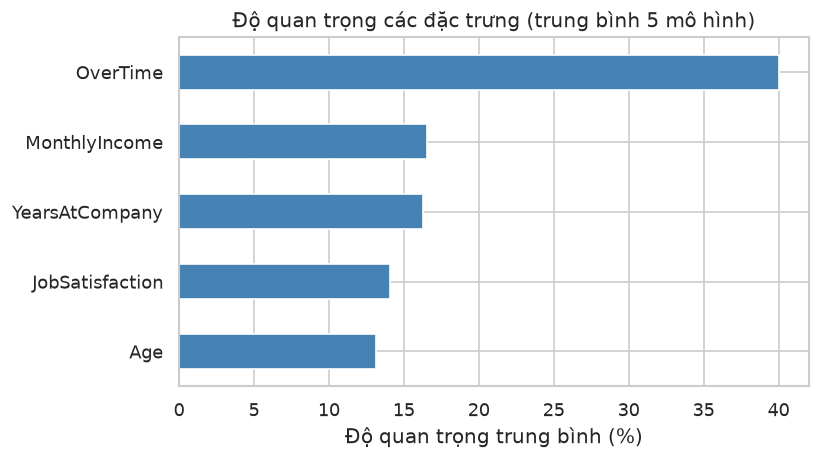

In [48]:
fig, ax = plt.subplots(figsize=(7, 4))
fi_norm["Trung bình"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Độ quan trọng trung bình (%)")
ax.set_title("Độ quan trọng các đặc trưng (trung bình 5 mô hình)")
fig.tight_layout()
plt.show()

## BƯỚC 9: Tổng kết và lựa chọn mô hình

In [49]:
best = test_table.sort_values(["Recall", "F1-score"], ascending=False).iloc[0]
print("Mô hình tốt nhất trên tập Test (ưu tiên Recall):")
print(f"  -> {best['Model']}")
print(f"     Recall={best['Recall']:.4f}, F1={best['F1-score']:.4f}, "
      f"ROC-AUC={best['ROC-AUC']:.4f}, Accuracy={best['Accuracy']:.4f}")
print("\nBảng so sánh cuối cùng (sắp xếp theo Recall):")
display(ranked.round(4))
print(f"\nCác bảng .csv đã được lưu tại thư mục: {OUT_DIR}")

Mô hình tốt nhất trên tập Test (ưu tiên Recall):
  -> Logistic Regression
     Recall=0.7872, F1=0.4713, ROC-AUC=0.7778, Accuracy=0.7177

Bảng so sánh cuối cùng (sắp xếp theo Recall):


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Balanced Acc
0,Logistic Regression,0.7177,0.3364,0.7872,0.4713,0.7778,0.7458
2,SVM,0.7313,0.3333,0.6809,0.4476,0.7772,0.7109
4,MLP (Deep Learning),0.7143,0.3093,0.6383,0.4167,0.7231,0.6835
3,XGBoost,0.7721,0.3077,0.3404,0.3232,0.7076,0.5973
1,Random Forest,0.7925,0.3056,0.2340,0.2651,0.7375,0.5664



Các bảng .csv đã được lưu tại thư mục: ket_qua
